# Aplicación de la herramienta a un segundo día completo

**Trabajo final · Aprendizaje Automático I** — Celia Sáenz Villalta

En `trabajo_bots_vs_humanos.ipynb` se entrenó el modelo con las primeras 24 horas del log de la tienda zanbil.ir (del 22/01/2019 a las 03:56 al 23/01/2019 a las 03:56) y se construyó la herramienta `analizar_log`. En este cuaderno se aplica esa herramienta, **sin reentrenar el modelo**, a las **24 horas siguientes** del mismo log (del 23/01 a las 03:56 al 24/01 a las 03:56).

Es una prueba sobre datos que el modelo no ha visto, pero de la misma web y de la misma época, de modo que permite responder a tres preguntas:

1. ¿Cómo se reparte el tráfico de ordenador del segundo día entre humanos, bots declarados y bots camuflados?
2. ¿Mantienen los grupos de comportamiento el mismo perfil que el día de entrenamiento?
3. ¿Se conserva la concordancia con el *user-agent* que se obtuvo en el entrenamiento?

In [1]:
import re, gzip, zipfile, io, glob, os, hashlib, pickle, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 80)
sns.set_theme(style='whitegrid')

SEMILLA = 0
N_INIT = 50
RUTA_2019 = 'datos/zaker2019_kaggle.zip'
RUTA_DIA2 = 'datos/zaker2019_dia2.log'
os.makedirs('figuras', exist_ok=True)

with open('modelos/modelo_2019.pkl', 'rb') as f:
    modelo19 = pickle.load(f)
VARIABLES = modelo19['variables']
print(f"Modelo cargado: k = {modelo19['k']}, variables = {VARIABLES}")

Modelo cargado: k = 7, variables = ['n_peticiones', 'media_dt', 'cv_dt', 'pct_estaticos', 'pct_4xx', 'pidio_robots', 'pct_sin_referer', 'pct_head', 'pct_urls_distintas']


Las funciones de carga, construcción de sesiones, etiquetado y clasificación, incluida `analizar_log`, son las del cuaderno principal; se copian aquí para que este cuaderno pueda ejecutarse de forma independiente.

In [2]:
PATRON_COMBINED = re.compile(
    r'^(?P<ip>\S+) \S+ \S+ \[(?P<fecha>[^\]]+)\] '
    r'"(?P<metodo>[A-Z]+) (?P<url>\S+)(?: \S+)?" '
    r'(?P<codigo>\d{3}) (?P<tamano>\d+|-) '
    r'"(?P<referer>[^"]*)" "(?P<user_agent>[^"]*)"'
)

def _abrir(ruta):
    """Abre un log en modo texto, tanto si es plano como si está comprimido (.gz o .zip)."""
    if ruta.endswith('.gz'):
        return gzip.open(ruta, 'rt', encoding='utf-8', errors='replace')
    if ruta.endswith('.zip'):
        z = zipfile.ZipFile(ruta)
        miembro = max(z.infolist(), key=lambda i: i.file_size)   # el log es el fichero más grande
        return io.TextIOWrapper(z.open(miembro), encoding='utf-8', errors='replace')
    return open(ruta, encoding='utf-8', errors='replace')

def anonimizar(ip):
    return hashlib.md5(ip.encode()).hexdigest()[:10]

FORMATO_FECHA = '%d/%b/%Y:%H:%M:%S %z'

def cargar_log(ruta, n_lineas=None, horas=None, anonimizar_ip=True, verbose=True):
    """Lee un log en formato combined y devuelve un DataFrame con una petición por fila.

    n_lineas: máximo de líneas a leer. horas: lee solo las primeras `horas` horas desde la primera petición.
    """
    rutas = sorted(glob.glob(ruta)) if isinstance(ruta, str) else list(ruta)
    filas, leidas, malas, limite, parar = [], 0, 0, None, False
    for r in rutas:
        with _abrir(r) as f:
            for linea in f:
                if n_lineas is not None and leidas >= n_lineas:
                    break
                leidas += 1
                m = PATRON_COMBINED.match(linea)
                if not m:
                    malas += 1
                    continue
                filas.append(m.groupdict())
                if horas is not None and (limite is None or len(filas) % 10_000 == 0):
                    try:
                        t = pd.to_datetime(filas[-1]['fecha'], format=FORMATO_FECHA)
                    except ValueError:
                        continue
                    if limite is None:
                        limite = t + pd.Timedelta(hours=horas)
                    elif t > limite:          # se comprueba cada 10 000 líneas; luego se recorta exacto
                        parar = True
                        break
        if parar:
            break
    df = pd.DataFrame(filas)
    df['fecha'] = pd.to_datetime(df['fecha'], format=FORMATO_FECHA, errors='coerce')
    malas += df['fecha'].isna().sum()
    df = df.dropna(subset=['fecha'])
    if limite is not None:
        df = df[df['fecha'] < limite]
    df['codigo'] = df['codigo'].astype(int)
    df['tamano'] = pd.to_numeric(df['tamano'], errors='coerce').fillna(0).astype(int)
    if anonimizar_ip:
        df['ip'] = df['ip'].map(anonimizar)
    if verbose:
        print(f'{len(rutas)} fichero(s), {leidas:,} líneas leídas, {malas:,} descartadas '
              f'({malas / max(leidas, 1):.4%})')
    return df.reset_index(drop=True)

EXT_ESTATICOS = re.compile(
    r'(?:\.(?:css|js|png|jpe?g|gif|svg|ico|webp|woff2?|ttf|eot|map|mp4|webm)(?:\?|$))'
    r'|^/(?:images?|static|styles?|scripts|js|css|plugins|fonts|assets)/', re.I)

CANDIDATAS = ['n_peticiones', 'duracion_s', 'pet_por_min', 'media_dt', 'cv_dt', 'pct_estaticos',
              'pct_4xx', 'pidio_robots', 'pct_sin_referer', 'pct_head', 'pct_urls_distintas']

VARIABLES_LOG = ['n_peticiones', 'duracion_s', 'pet_por_min', 'media_dt', 'cv_dt']

def crear_sesiones(df, inactividad_min=30):
    """Asigna a cada petición un identificador de sesión (misma IP y user-agent, corte por inactividad)."""
    df = df.sort_values(['ip', 'user_agent', 'fecha']).reset_index(drop=True)
    cambio = (df['ip'] != df['ip'].shift()) | (df['user_agent'] != df['user_agent'].shift())
    hueco = df['fecha'].diff().dt.total_seconds()
    nueva = cambio | (hueco > inactividad_min * 60)
    df['sesion'] = nueva.cumsum()
    df['dt'] = hueco.where(~nueva)        # segundos desde la petición anterior de la misma sesión
    return df

def calcular_variables(df):
    """Una fila por sesión con las variables de comportamiento."""
    d = df.assign(estatico=df['url'].str.contains(EXT_ESTATICOS),
                  error4xx=df['codigo'].between(400, 499),
                  robots=df['url'].str.contains(r'robots\.txt|sitemap', case=False),
                  sin_referer=df['referer'].isin(['-', '']),
                  head=df['metodo'].eq('HEAD'))
    g = d.groupby('sesion')
    ses = pd.DataFrame({
        'ip': g['ip'].first(),
        'user_agent': g['user_agent'].first(),
        'inicio': g['fecha'].min(),
        'n_peticiones': g.size(),
        'duracion_s': (g['fecha'].max() - g['fecha'].min()).dt.total_seconds(),
        'media_dt': g['dt'].mean(),
        'std_dt': g['dt'].std(ddof=0),
        'pct_estaticos': g['estatico'].mean(),
        'pct_4xx': g['error4xx'].mean(),
        'pidio_robots': g['robots'].max().astype(int),
        'pct_sin_referer': g['sin_referer'].mean(),
        'pct_head': g['head'].mean(),
        'pct_urls_distintas': g['url'].nunique() / g.size(),
    })
    ses['pet_por_min'] = ses['n_peticiones'] / np.maximum(ses['duracion_s'], 1) * 60
    ses['cv_dt'] = (ses['std_dt'] / ses['media_dt'].replace(0, np.nan)).fillna(0)
    return ses

BOTS = re.compile(
    r'bot|crawl|spider|slurp|uptime|monitor|curl|python|wget|scan|go-http|java/|libwww|okhttp|'
    r'axios|node-fetch|headless|phantom|httpclient|facebookexternalhit|zgrab|masscan|nmap|nikto|'
    r'sqlmap|feed|fetch|preview|^-?$', re.I)

def etiqueta_ua(ua):
    if BOTS.search(ua):
        return 'bot_declarado'
    return 'navegador'

MOVIL = re.compile(r'Android|iPhone|iPad|iPod|\biOS\b|Mobile|Dalvik|CFNetwork|NetworkingExtension|'
                   r'Windows Phone|BlackBerry|Opera Mini|webOS|KaiOS|SamsungBrowser', re.I)

def es_movil(ses):
    """Sesiones de navegador con user-agent móvil (los bots declarados nunca se marcan)."""
    return ses['user_agent'].str.contains(MOVIL) & ses['tipo_ua'].eq('navegador')

def tipo_cliente(ua):
    if etiqueta_ua(ua) != 'navegador':
        return 'bot declarado'
    return 'móvil' if MOVIL.search(ua) else 'ordenador'

def matriz(ses, variables=None):
    """Matriz de variables transformadas con log(1+x) cuando procede (sin estandarizar)."""
    variables = VARIABLES if variables is None else variables
    X = ses[variables].copy()
    logv = [v for v in variables if v in VARIABLES_LOG]
    X[logv] = np.log1p(X[logv])
    return X

def evaluar_kmeans(Z, ks, muestra):
    filas = []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEMILLA).fit(Z)
        filas.append({'k': k, 'inercia': km.inertia_,
                      'silhouette': silhouette_score(Z[muestra], km.labels_[muestra]),
                      'calinski_harabasz': calinski_harabasz_score(Z, km.labels_),
                      'davies_bouldin': davies_bouldin_score(Z, km.labels_)})
    return pd.DataFrame(filas).set_index('k')

def dibujar_metricas(met, titulo, fichero=None):
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
    for a, col in zip(ax, met.columns):
        a.plot(met.index, met[col], 'o-'); a.set_title(col); a.set_xlabel('k')
    fig.suptitle(titulo); plt.tight_layout()
    if fichero: plt.savefig(fichero, dpi=150)
    plt.show()

def perfil(datos, etiquetas):
    return datos[VARIABLES].groupby(etiquetas).median().assign(
        sesiones=pd.Series(etiquetas).value_counts().sort_index().values,
        peticiones=datos.groupby(etiquetas)['n_peticiones'].sum().values)

def nombrar(p):
    """Nombre y tipo de un clúster a partir de las medianas de su perfil."""
    if p['pct_head'] > 0.5:          return 'monitorización (HEAD)', 'automatizado'
    if p['pidio_robots'] > 0.5:      return 'crawler (pide robots.txt)', 'automatizado'
    if p['pct_4xx'] > 0.5:           return 'errores 4xx / sondeo', 'automatizado'
    if p['media_dt'] > 300 and p['pct_sin_referer'] >= 0.5:
        return 'crawler lento y regular', 'automatizado'
    if p['pct_sin_referer'] < 0.5:
        return ('navegación humana' if p['n_peticiones'] >= 10 else 'visita corta'), 'humano'
    if p['pct_estaticos'] >= 0.5:    return 'recursos sueltos sin referer', 'ambiguo'
    return 'acceso directo sin referer ni estáticos', 'ambiguo'

def nombrar_clusters(datos, etiquetas):
    p = perfil(datos, etiquetas)
    nombres = {c: nombrar(fila) for c, fila in p.iterrows()}
    return p.assign(nombre=[nombres[c][0] for c in p.index], tipo=[nombres[c][1] for c in p.index]), nombres

def mapa_perfil(Z, etiquetas, p, titulo, fichero=None):
    medias_z = pd.DataFrame(Z, columns=VARIABLES).groupby(etiquetas).mean()
    filas = [f'{c}: {p.loc[c, "nombre"]} (n={p.loc[c, "sesiones"]:,})' for c in medias_z.index]
    fig, ax = plt.subplots(figsize=(14, 0.6 * len(filas) + 1.5))
    sns.heatmap(medias_z.clip(-2.5, 2.5), annot=p[VARIABLES].round(2).values, fmt='', cmap='RdBu_r',
                center=0, yticklabels=filas, ax=ax, cbar_kws={'label': 'media estandarizada'})
    ax.set_title(titulo); plt.tight_layout()
    if fichero: plt.savefig(fichero, dpi=150)
    plt.show()

CATEGORIAS = ['humano', 'ambiguo', 'bot camuflado', 'bot declarado', '1 petición (sin clasificar)']

COLORES = dict(zip(CATEGORIAS, ['#4C72B0', '#A0A0A0', '#C44E52', '#DD8452', '#D9D9D9']))

def entrenar_modelo(ses, k):
    """Entrena k-means sobre las sesiones (ya filtradas) con ≥ 2 peticiones y nombra los clústeres."""
    datos = ses[ses['n_peticiones'] > 1]
    esc = StandardScaler().fit(matriz(datos))
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEMILLA).fit(esc.transform(matriz(datos)))
    _, nombres = nombrar_clusters(datos, km.labels_)
    return {'escalador': esc, 'kmeans': km, 'nombres': nombres}

def clasificar_sesiones(ses, modelo, solo_escritorio=True):
    ses = ses.copy()
    ses['tipo_ua'] = ses['user_agent'].map(etiqueta_ua)
    if solo_escritorio:
        movil = es_movil(ses)
        print(f'Sesiones móviles excluidas: {movil.sum():,} ({movil.mean():.1%})')
        ses = ses[~movil].copy()
    validas = ses['n_peticiones'] > 1
    ses['cluster'] = -1
    ses.loc[validas, 'cluster'] = modelo['kmeans'].predict(modelo['escalador'].transform(matriz(ses[validas])))
    ses['grupo'] = ses['cluster'].map(lambda c: modelo['nombres'].get(c, ('—', '—'))[0])
    tipo = ses['cluster'].map(lambda c: modelo['nombres'].get(c, ('—', '—'))[1])
    ses['categoria'] = np.select(
        [ses['tipo_ua'] == 'bot_declarado', ~validas, tipo == 'automatizado', tipo == 'humano'],
        ['bot declarado', '1 petición (sin clasificar)', 'bot camuflado', 'humano'],
        default='ambiguo')
    return ses

def analizar_log(ruta, modelo, n_lineas=None, horas=None, titulo=None, dibujar=True, devolver_sesiones=False):
    """Estima qué parte del tráfico de un log es humana y qué parte automatizada."""
    log = crear_sesiones(cargar_log(ruta, n_lineas=n_lineas, horas=horas))
    ses = clasificar_sesiones(calcular_variables(log), modelo)
    res = pd.DataFrame({
        'sesiones': ses['categoria'].value_counts(),
        'peticiones': ses.groupby('categoria')['n_peticiones'].sum()}).reindex(CATEGORIAS).fillna(0).astype(int)
    res['% sesiones'] = (100 * res['sesiones'] / res['sesiones'].sum()).round(1)
    res['% peticiones'] = (100 * res['peticiones'] / res['peticiones'].sum()).round(1)
    if dibujar:
        fig, ax = plt.subplots(figsize=(10, 2.6))
        izq = np.zeros(2)
        for cat in CATEGORIAS:
            v = res.loc[cat, ['% sesiones', '% peticiones']].values.astype(float)
            ax.barh(['sesiones', 'peticiones'], v, left=izq, color=COLORES[cat], label=cat)
            for i, x in enumerate(v):
                if x >= 4: ax.text(izq[i] + x / 2, i, f'{x:.0f}%', ha='center', va='center', fontsize=9)
            izq += v
        ax.set(xlim=(0, 100), xlabel='%', title=titulo or ruta)
        ax.legend(ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.35), loc='upper center')
        plt.tight_layout()
        if titulo: plt.savefig(f'figuras/analizar_{re.sub(r"\W+", "_", titulo)}.png', dpi=150, bbox_inches='tight')
        plt.show()
    return (res, ses) if devolver_sesiones else res

## 1. Extracción del segundo día

El log completo ocupa 3,5 GB, de modo que se recorre el fichero comprimido y se guardan en un fichero aparte solo las líneas cuya fecha cae en la ventana del segundo día. La ventana se calcula a partir de la primera petición del log, igual que en el entrenamiento, para que los dos días sean consecutivos y no se solapen. Como el log está prácticamente ordenado por fecha, la lectura se detiene poco después de superar el final de la ventana.

In [3]:
def fecha_linea(linea):
    i = linea.find('[')
    try:
        return datetime.strptime(linea[i + 1:i + 27], '%d/%b/%Y:%H:%M:%S %z')
    except ValueError:
        return None

def extraer_ventana(ruta, desde, hasta, destino, margen_min=10):
    """Copia a `destino` las líneas del log con fecha en [desde, hasta)."""
    leidas = escritas = 0
    tope = hasta + pd.Timedelta(minutes=margen_min)
    with _abrir(ruta) as f, open(destino, 'w', encoding='utf-8') as g:
        for linea in f:
            leidas += 1
            t = fecha_linea(linea)
            if t is None:
                continue
            if t >= tope:
                break
            if desde <= t < hasta:
                g.write(linea)
                escritas += 1
    print(f'{leidas:,} líneas recorridas, {escritas:,} escritas en {destino}')

with _abrir(RUTA_2019) as f:
    inicio_dia1 = fecha_linea(f.readline())
inicio_dia2 = inicio_dia1 + pd.Timedelta(hours=24)
fin_dia2 = inicio_dia2 + pd.Timedelta(hours=24)
print('Día 1 (entrenamiento):', inicio_dia1, '→', inicio_dia2)
print('Día 2 (este cuaderno):', inicio_dia2, '→', fin_dia2)

if not os.path.exists(RUTA_DIA2):
    extraer_ventana(RUTA_2019, inicio_dia2, fin_dia2, RUTA_DIA2)
else:
    print(f'{RUTA_DIA2} ya existe; se reutiliza')

Día 1 (entrenamiento): 2019-01-22 03:56:14+03:30 → 2019-01-23 03:56:14+03:30
Día 2 (este cuaderno): 2019-01-23 03:56:14+03:30 → 2019-01-24 03:56:14+03:30
datos/zaker2019_dia2.log ya existe; se reutiliza


## 2. Tráfico a lo largo del segundo día

Antes de aplicar la herramienta se representa, igual que en el cuaderno principal, cómo se reparten las peticiones a lo largo del día entre navegadores de ordenador, navegadores móviles y bots declarados.

1 fichero(s), 2,325,357 líneas leídas, 80 descartadas (0.0034%)


Intervalo temporal: 2019-01-23 03:56:14+03:30 → 2019-01-24 03:56:12+03:30


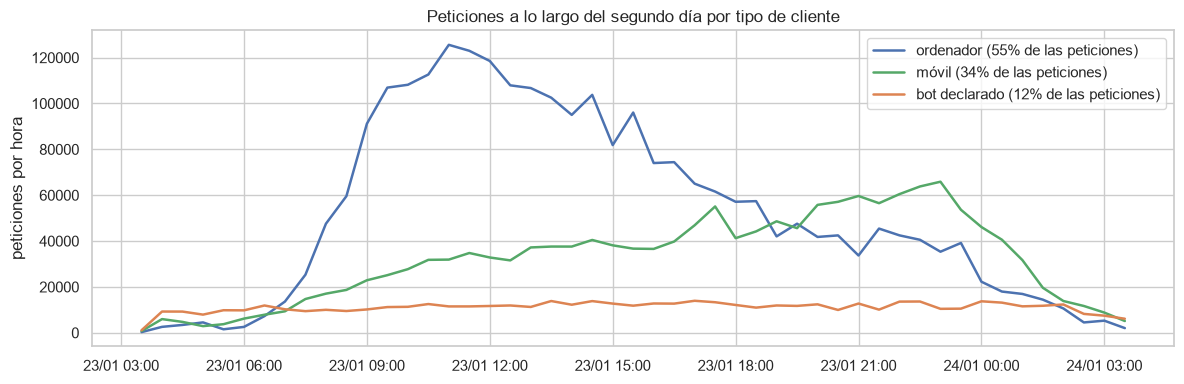

user_agent,bot declarado,móvil,ordenador
franja (hora local),,,
00–06 h,28.7,46.2,25.1
06–12 h,10.7,20.7,68.6
12–18 h,8.9,27.5,63.6
18–24 h,10.6,49.5,39.8


In [4]:
log_d2 = cargar_log(RUTA_DIA2)
print('Intervalo temporal:', log_d2['fecha'].min(), '→', log_d2['fecha'].max())

uas = log_d2['user_agent'].unique()
cliente = log_d2['user_agent'].map(dict(zip(uas, map(tipo_cliente, uas))))
por_hora = (log_d2.assign(cliente=cliente).set_index('fecha')
            .groupby('cliente').resample('30min').size().unstack(0).fillna(0) * 2)

fig, ax = plt.subplots(figsize=(12, 4))
for c, color in [('ordenador', '#4C72B0'), ('móvil', '#55A868'), ('bot declarado', '#DD8452')]:
    ax.plot(por_hora.index, por_hora[c], label=f'{c} ({cliente.eq(c).mean():.0%} de las peticiones)',
            color=color, lw=1.8)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %H:%M', tz=por_hora.index.tz))
ax.set(ylabel='peticiones por hora', title='Peticiones a lo largo del segundo día por tipo de cliente')
ax.legend(); plt.tight_layout(); plt.savefig('figuras/peticiones_dia2_2019.png', dpi=150); plt.show()

franja = pd.cut(log_d2['fecha'].dt.hour, bins=[0, 6, 12, 18, 24], right=False,
                labels=['00–06 h', '06–12 h', '12–18 h', '18–24 h'])
pd.crosstab(franja, cliente, normalize='index').mul(100).round(1).rename_axis('franja (hora local)')

**// Comentario:** El segundo día contiene 2 325 357 peticiones, un volumen casi idéntico al del día de entrenamiento, y el reparto entre tipos de cliente se repite: el **ordenador** genera el 55 % de las peticiones, el **móvil** el 34 % y los **bots declarados** el 12 %. La forma de las curvas también se mantiene: el ordenador alcanza su máximo, unas 125 000 peticiones por hora, hacia las 11:00 y decae por la tarde; el móvil crece durante el día, supera al ordenador a partir de las 19:00–20:00 y llega a su máximo hacia las 23:00; y los bots mantienen un ritmo casi constante, de 10 000 a 14 000 peticiones por hora, de modo que entre las 00:00 y las 06:00 suponen el 28,7 % de las peticiones. **El patrón diario es estable de un día a otro**, lo que indica que el día de entrenamiento era representativo del tráfico habitual de la tienda.

## 3. Resultado de `analizar_log` y comparación con el día de entrenamiento

1 fichero(s), 2,325,357 líneas leídas, 80 descartadas (0.0034%)


Sesiones móviles excluidas: 51,323 (67.0%)


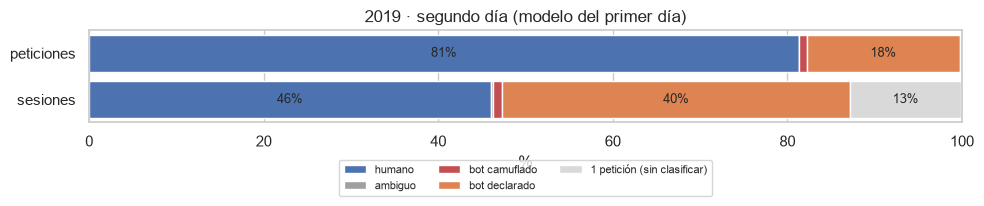

,sesiones,peticiones,% sesiones,% peticiones
categoria,,,,
humano,11611,1253740,46.0,81.3
ambiguo,79,433,0.3,0.0
bot camuflado,261,13525,1.0,0.9
bot declarado,10067,271227,39.9,17.6
1 petición (sin clasificar),3204,3204,12.7,0.2


día 1 (entrenamiento)                            día 2                        
                                         sesiones % sesiones % peticiones sesiones % sesiones % peticiones
categoria                                                                                                 
humano                                      11667       47.5         81.8    11611       46.0         81.3
ambiguo                                        80        0.3          0.0       79        0.3          0.0
bot camuflado                                 229        0.9          0.7      261        1.0          0.9
bot declarado                                8984       36.5         17.3    10067       39.9         17.6
1 petición (sin clasificar)                  3624       14.7          0.2     3204       12.7          0.2

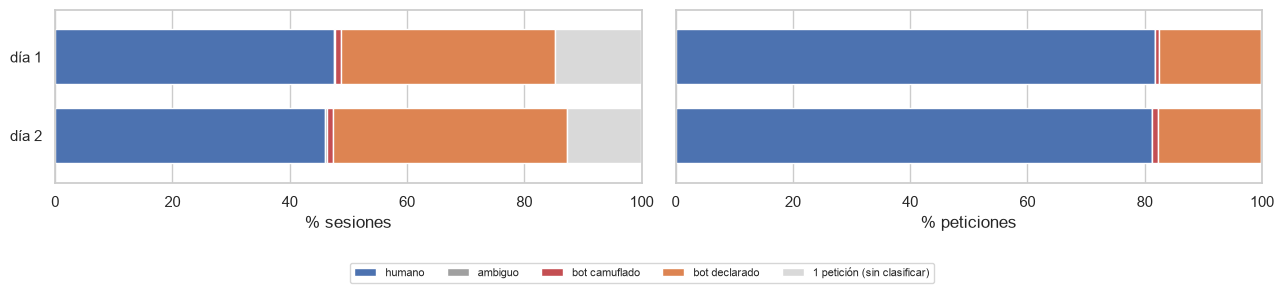

In [5]:
res_d2, ses_d2 = analizar_log(RUTA_DIA2, modelo19, titulo='2019 · segundo día (modelo del primer día)',
                              devolver_sesiones=True)
display(res_d2)

res_d1 = modelo19['resumen_2019']
comp = pd.concat({'día 1 (entrenamiento)': res_d1, 'día 2': res_d2}, axis=1)
comp = comp.loc[:, (slice(None), ['sesiones', '% sesiones', '% peticiones'])]
display(comp)

fig, ax = plt.subplots(1, 2, figsize=(13, 2.8), sharey=True)
for a, col in zip(ax, ['% sesiones', '% peticiones']):
    t = pd.DataFrame({'día 1': res_d1[col], 'día 2': res_d2[col]})
    t.T.plot.barh(stacked=True, ax=a, color=[COLORES[c] for c in CATEGORIAS], legend=False, width=0.7)
    a.set(xlim=(0, 100), xlabel=col)
ax[0].invert_yaxis()
fig.legend(CATEGORIAS, ncol=5, fontsize=8, loc='lower center', bbox_to_anchor=(0.5, -0.06))
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.savefig('figuras/comparacion_dia1_dia2.png', dpi=150); plt.show()

**// Comentario:** Tras excluir 51 323 sesiones móviles (el 67,0 %), la herramienta estima para el segundo día un reparto muy similar al del día de entrenamiento: el tráfico humano supone el 46,0 % de las sesiones y el **81,3 % de las peticiones** (frente al 47,5 % y al 81,8 %), los bots declarados el 39,9 % de las sesiones y el 17,6 % de las peticiones, y las sesiones de una sola petición el 12,7 % de las sesiones pero solo el 0,2 % de las peticiones. Los **bots camuflados** pasan de 229 a **261 sesiones** (del 0,9 % al 1,0 % de las sesiones), una variación pequeña. **El modelo entrenado con un día produce estimaciones coherentes al aplicarlo al día siguiente**, sin necesidad de reentrenarlo.

## 4. ¿Mantienen los grupos el mismo perfil?

Que la herramienta asigne cada sesión a un grupo no garantiza que el grupo siga significando lo mismo. Para comprobarlo se compara, para cada grupo:

- su **peso** (porcentaje de sesiones analizables) el día de entrenamiento y el segundo día;
- su **perfil medio**: el centroide aprendido por k-means frente a la media de las sesiones del segundo día asignadas a él, ambos calculados en la escala transformada y devueltos a unidades originales.

In [6]:
km, esc, nombres = modelo19['kmeans'], modelo19['escalador'], modelo19['nombres']
v2 = ses_d2[ses_d2['cluster'] >= 0].copy()

def a_unidades(Xt):
    X = pd.DataFrame(Xt, columns=VARIABLES)
    logv = [c for c in VARIABLES if c in VARIABLES_LOG]
    X[logv] = np.expm1(X[logv])
    return X

centroides = a_unidades(esc.inverse_transform(km.cluster_centers_))
medias_d2 = a_unidades(matriz(v2).groupby(v2['cluster'].values).mean().reindex(range(km.n_clusters)).values)

peso = pd.DataFrame({
    'grupo': [nombres[c][0] for c in range(km.n_clusters)],
    '% día 1': pd.Series(km.labels_).value_counts(normalize=True).sort_index().mul(100).round(1).values,
    '% día 2': v2['cluster'].value_counts(normalize=True).reindex(range(km.n_clusters)).fillna(0).mul(100).round(1).values})
display(peso)

clave = ['n_peticiones', 'media_dt', 'cv_dt', 'pct_estaticos', 'pct_sin_referer']
perfiles = pd.concat({'día 1 (centroide)': centroides[clave], 'día 2 (media)': medias_d2[clave]}, axis=1)
perfiles.index = [f'{c}: {nombres[c][0]}' for c in range(km.n_clusters)]
perfiles.swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False).round(2)

,grupo,% día 1,% día 2
0,navegación humana,50.4,47.6
1,crawler lento y regular,22.4,22.5
2,visita corta,19.3,22.3
3,acceso directo sin referer ni estáticos,1.0,0.9
4,monitorización (HEAD),0.1,0.2
5,crawler (pide robots.txt),1.2,1.5
6,visita corta,5.6,5.1


cv_dt                        media_dt                    n_peticiones                   pct_estaticos                 pct_sin_referer  \
                                           día 1 (centroide) día 2 (media) día 1 (centroide) día 2 (media) día 1 (centroide) día 2 (media) día 1 (centroide) día 2 (media) día 1 (centroide)   
0: navegación humana                                    5.20          5.16              1.55          1.56             99.54         98.12              0.89          0.89              0.02   
1: crawler lento y regular                              0.27          0.29            532.69        520.80              3.24          3.39              0.01          0.03              0.99   
2: visita corta                                         0.59          0.56              5.69          5.67              4.42          4.56              0.87          0.82              0.21   
3: acceso directo sin referer ni estáticos              0.36          0.34             31.18         27.97              3.28          3.20              0.11          0.13              0.78   
4: monitorización (HEAD)                                0.73          0.61             27.13         19.46             18.44         12.28              0.00          0.04              0.52   
5: crawler (pide robots.txt)                            1.45          1.48              5.23          3.72             23.15         23.65              0.36          0.39              0.65   
6: visita corta                                         1.35          1.39             10.24         13.53             13.58         14.13              0.56          0.57              0.47   

                                                          
                                           día 2 (media)  
0: navegación humana                                0.02  
1: crawler lento y regular                          0.99  
2: visita corta                                     0.29  
3: acceso directo sin referer ni estáticos          0.73  
4: monitorización (HEAD)                            0.67  
5: crawler (pide robots.txt)                        0.61  
6: visita corta                                     0.46

**// Comentario:** Los grupos conservan tanto su peso como su significado. La navegación humana pasa del 50,4 % al 47,6 % de las sesiones analizables, el crawler lento se mantiene (22,4 % frente a 22,5 %) y la visita corta principal crece del 19,3 % al 22,3 %. Los perfiles medios del segundo día prácticamente coinciden con los centroides aprendidos: la navegación humana mantiene unas 98 peticiones por sesión, 1,56 s entre peticiones, un coeficiente de variación de 5,16 y un 89 % de estáticos (frente a 99,5; 1,55 s; 5,20 y 89 %), y el crawler lento sigue pidiendo una página cada 521 s con un coeficiente de variación de 0,29 (frente a 533 s y 0,27). Las únicas diferencias apreciables aparecen en el grupo de monitorización, que es muy pequeño (en torno a 25 sesiones) y por tanto más sensible a casos concretos. **El modelo no solo asigna las sesiones, sino que los grupos siguen describiendo el mismo comportamiento.**

## 5. Concordancia con el *user-agent* y bots camuflados

Se repite la validación de la sección 5 del cuaderno principal sobre las sesiones del segundo día: composición de cada grupo según el *user-agent* y ARI binario entre los grupos automatizados y los bots declarados.

In [7]:
tabla = pd.crosstab(v2['grupo'], v2['tipo_ua'], margins=True)
tabla['% bot_declarado'] = (100 * tabla['bot_declarado'] / tabla['All']).round(1)
display(tabla)

auto = v2['cluster'].map(lambda c: nombres[c][1]).eq('automatizado')
bot = v2['tipo_ua'].ne('navegador')
print('ARI binario (grupo automatizado vs UA de bot):', round(adjusted_rand_score(bot, auto), 3))
print(f'Sesiones con UA de bot que caen en grupos automatizados: {auto[bot].mean():.1%}')
print(f'Sesiones con UA de navegador que caen en grupos automatizados: {auto[~bot].mean():.1%}')

tipo_ua,bot_declarado,navegador,All,% bot_declarado
grupo,,,,
acceso directo sin referer ni estáticos,77,79,156,49.4
crawler (pide robots.txt),117,137,254,46.1
crawler lento y regular,3775,111,3886,97.1
monitorización (HEAD),15,13,28,53.6
navegación humana,92,8142,8234,1.1
visita corta,1272,3469,4741,26.8
All,5348,11951,17299,30.9


ARI binario (grupo automatizado vs UA de bot): 0.631
Sesiones con UA de bot que caen en grupos automatizados: 73.1%
Sesiones con UA de navegador que caen en grupos automatizados: 2.2%


In [8]:
# ¿Qué bots declarados caen en las visitas cortas?
b = v2[(v2['grupo'] == 'visita corta') & bot]
display(b['user_agent'].str[:70].value_counts().head(6).to_frame('sesiones en visita corta'))

# Efecto de BingPreview (generador de vistas previas de Bing) sobre la concordancia
bp = v2['user_agent'].str.contains('BingPreview')
print(f'Sesiones de BingPreview: {bp.sum():,} (de ellas {(bp & v2["grupo"].eq("visita corta")).sum():,} en visitas cortas)')
print('ARI binario sin BingPreview:', round(adjusted_rand_score(bot[~bp], auto[~bp]), 3))
print(f'Bots declarados (sin BingPreview) en grupos automatizados: {auto[bot & ~bp].mean():.1%}')

,sesiones en visita corta
user_agent,
"Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKit/534+ (KHTML, like Geck",713
Mozilla/5.0 (compatible; Parsijoobot; +http://www.parsijoo.ir/bot.html,143
Mozilla/5.0 (Linux; Android 6.0.1; Nexus 5X Build/MMB29P) AppleWebKit/,77
okhttp/2.5.0,72
Googlebot-Image/1.0,63
Mozilla/5.0 (compatible; bingbot/2.0; +http://www.bing.com/bingbot.htm,60


Sesiones de BingPreview: 853 (de ellas 725 en visitas cortas)
ARI binario sin BingPreview: 0.775
Bots declarados (sin BingPreview) en grupos automatizados: 85.2%


In [9]:
camuflados = v2[(v2['tipo_ua'] == 'navegador') & auto]
print(f'Bots camuflados el segundo día: {len(camuflados):,} sesiones '
      f'({len(camuflados) / len(v2):.1%} de las sesiones analizables)')
display(camuflados['grupo'].value_counts().to_frame('sesiones'))

COLS = ['ip', 'user_agent', 'n_peticiones', 'duracion_s', 'media_dt', 'cv_dt', 'pct_estaticos',
        'pct_sin_referer', 'pidio_robots', 'grupo']
camuflados.nlargest(3, 'n_peticiones')[COLS].round(2)

Bots camuflados el segundo día: 261 sesiones (1.5% de las sesiones analizables)


,sesiones
grupo,
crawler (pide robots.txt),137
crawler lento y regular,111
monitorización (HEAD),13


,ip,user_agent,n_peticiones,duracion_s,media_dt,cv_dt,pct_estaticos,pct_sin_referer,pidio_robots,grupo
sesion,,,,,,,,,,
61198,cc4e74f046,Mozilla/4.0 (compatible; MSIE 5.01; Windows NT 5.0),473,6389.0,13.54,0.90,0.00,1.00,0,crawler lento y regular
61196,cc4e74f046,Mozilla/4.0 (compatible; MSIE 5.01; Windows NT 5.0),470,5470.0,11.66,0.90,0.00,1.00,0,crawler lento y regular
22154,49a8620bc1,Mozilla/5.0 (Windows NT 6.1; Win64; x64; rv:64.0) Gecko/20100101 Firefox/64.0,468,294.0,0.63,5.33,0.91,0.04,1,crawler (pide robots.txt)


**// Comentario:** La concordancia con el *user-agent* se mantiene en lo esencial: la navegación humana solo contiene un 1,1 % de bots declarados y el crawler lento un 97,1 %, y apenas el 2,2 % de las sesiones de navegador caen en grupos automatizados. Sin embargo, el ARI binario baja a 0,631 y solo el 73,1 % de los bots declarados caen en grupos automatizados, porque las visitas cortas pasan a contener un 26,8 % de bots. La causa es **BingPreview**, el servicio de Bing que genera vistas previas de páginas: suma 853 sesiones este día, 725 de ellas en las visitas cortas, ya que carga una página con sus recursos en pocos segundos, igual que una consulta humana breve. **Sin BingPreview el ARI binario es de 0,775 y el 85,2 % de los bots declarados caen en grupos automatizados**, valores incluso algo mejores que en el entrenamiento, por lo que la caída se debe a un cambio en la mezcla de bots y no a una pérdida de capacidad del modelo. En cuanto a los **bots camuflados**, se detectan 261 sesiones (137 que piden robots.txt, 111 en el crawler lento y 13 de monitorización). Los dos ejemplos con más peticiones proceden de **la misma IP que el falso Internet Explorer 5.01 identificado el día de entrenamiento**, que vuelve a aparecer con el mismo patrón (unas 470 peticiones por sesión, una cada 12–14 s, sin *referer* ni estáticos). El tercero repite el comportamiento de navegador automatizado ya visto: un *user-agent* de Firefox en Windows 7 que pide `robots.txt` y realiza 468 peticiones en 294 s, una cada 0,63 s.

## 6. Conclusiones

- **La herramienta funciona sobre datos nuevos sin reentrenar.** Aplicada al día siguiente al de entrenamiento, estima un reparto del tráfico de ordenador casi idéntico (81,3 % de peticiones humanas frente a 81,8 %), con un número similar de bots camuflados (261 frente a 229).
- **Los grupos son estables.** Mantienen su peso y su perfil: los centroides aprendidos y las medias del segundo día prácticamente coinciden en todas las variables relevantes, salvo en el grupo de monitorización, que es muy pequeño.
- **La detección de bots camuflados es consistente.** El falso Internet Explorer 5.01 del día de entrenamiento reaparece desde la misma IP y vuelve a detectarse, y aparecen nuevos navegadores automatizados con el mismo patrón (lectura de `robots.txt` y una petición por segundo o menos).
- **La concordancia con el *user-agent* depende de la mezcla de bots.** El ARI binario baja de 0,744 a 0,631 por el aumento de BingPreview, cuyo comportamiento es indistinguible de una visita humana breve; sin él asciende a 0,775.

**Limitaciones.** La prueba se realiza con la misma web y con un día consecutivo, por lo que confirma la estabilidad temporal del modelo a corto plazo, pero no su validez en otros sitios web. Además, la validación sigue dependiendo de una etiqueta aproximada, y los bots que imitan visitas humanas breves, como BingPreview, no pueden separarse solo con estas variables de comportamiento.